# Plantellect - ConvNeXtTiny (fast pipeline, resumable)

Accuracy-first candidate: modern CNN, strong on fine texture such as venation. About 29M parameters, the heaviest of the three on CPU.

**How this notebook works**

1. **Data**: downloads the single archive `plantellect-dataset-latest.tar` from Drive once (or reuses a cache), decodes every photo **once** into a uint8 array at the model's input size and stores that cache on Drive. Later sessions copy one cache file instead of thousands of photos.
2. **Augmentation runs on the GPU** (flip, rotation, zoom, brightness, contrast). The CPU only slices arrays.
3. **Stage 1** trains the head on cached backbone features (minutes, not hours). **Stage 2** fine-tunes the top 40 backbone layers.
4. **Every run has its own folder** `plantellect/model/convnext_tiny/` with `train_state.json`, `history.csv`, `last.weights.h5` and `best.weights.h5`. If Colab disconnects, run the notebook again and it **resumes**. The best checkpoint is only replaced by a genuinely better one, across sessions and stages.

Runtime: *Runtime > Change runtime type > T4 GPU*.

### Cell 1 - imports

In [1]:
import os, io, re, json, csv, math, random, time, shutil, hashlib, itertools, subprocess, tarfile, zipfile
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from google.colab import drive

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except Exception:
        pass                      # already initialised: harmless
print("TF", tf.__version__, "| GPU:", gpus, "| CPU cores:", os.cpu_count())

TF 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | CPU cores: 2


### Cell 2 - Settings

In [2]:
RUN_NAME        = "convnext_tiny"
MODEL_ARCH      = "ConvNeXtTiny"
BUILDER         = tf.keras.applications.ConvNeXtTiny
SERVER_MODEL_ID = "convnexttiny"          # folder name the server expects (see the promote cell)
MODEL_NAME      = "plantellect_model"
MODEL_FILENAME  = MODEL_NAME + ".keras"

INPUT_SHAPE = (224, 224, 3)              # native size for this backbone
H, W = INPUT_SHAPE[:2]
BATCH_SIZE  = 64                    # stage 2. Raise until the GPU runs out of memory, then back off.
DROPOUT     = 0.5
LABEL_SMOOTHING = 0.0                    # 0.0 = same loss as the earlier B0 run

# ---- How photos become model input. MUST match preprocessing.json (written in cell 9)
# and therefore the server. Changing any of these means a new cache and a retrain.
RESIZE_METHOD  = "lanczos"               # nearest | bilinear | bicubic | lanczos | box | hamming
EXIF_TRANSPOSE = True                    # rotate phone photos upright first (ffmpeg already did for the dataset)
FAST_DECODE    = False                   # True: faster first build from full-size originals, tiny pixel differences

# ---- Stage 1: head only, backbone frozen
FEATURE_CACHE_STAGE1 = True              # train the head on cached backbone features (much faster)
FEATURE_AUG_COPIES   = 4                 # augmented copies of each train image used for those features
HEAD_EPOCHS = 50
HEAD_LR     = 1e-3
HEAD_BATCH  = 256
FEAT_BATCH  = 128                        # batch size while extracting features

# ---- Stage 2: fine-tune the top backbone layers (BatchNorm stays frozen)
FT_EPOCHS       = 20
FT_LR           = 2e-5
UNFREEZE_LAYERS = 40
EARLY_STOPPING_PATIENCE = 10
REDUCE_LR_PATIENCE      = 5

# Same shape-safe augmentation as before (no shear). Runs on the GPU, training only.
AUGMENTATION = {"rotation": 20, "zoom": 0.2, "horizontal_flip": True, "brightness": 0.2, "contrast": 0.2}

# ---- Speed
MIXED_PRECISION      = True           # fp16 compute on the T4; the exported model is fp32
USE_XLA              = False             # experiment: jit_compile=True can be faster, or fail on some layers
STEPS_PER_EXECUTION  = 1                 # try 4 or 8 for small models such as MobileNet
if MIXED_PRECISION:
    tf.keras.mixed_precision.set_global_policy("mixed_float16")

# ---- Checkpoints and resume
RESUME            = True                 # continue an interrupted run found in this run's folder
FRESH_START       = False                # True: move the old run files to _old_<time>/ and start over
MIN_DELTA         = 1e-4                 # best is replaced only if val_loss improves by more than this. 1e-3
CHANCE_GATE       = 3.0                  # ... and val_accuracy is at least this many times chance (3 / classes)
DRIVE_SYNC_EVERY  = 3                    # copy last.weights.h5 to Drive every N epochs (best: on every improvement)

# ---- Paths (everything lives under plantellect/ on Drive; there is no shared "main" folder)
DRIVE_ROOT      = "/content/drive/MyDrive/plantellect"
DATASET_DIR     = DRIVE_ROOT + "/dataset"
DATASET_NAME    = "plantellect-dataset-latest"          # .tar / .tar.gz / .zip, optional <name>.manifest.json next to it
CACHE_DRIVE_DIR = DRIVE_ROOT + "/cache"
FOLDER_FALLBACK = DRIVE_ROOT + "/plantellect_training"  # used only if no archive exists (slow, one time)
FOLDER_VERSION_TAG = "v1"                               # bump it when the fallback folder's photos change
PLANT_FOLDER    = "plant"                               # group folder holding one folder per species
OUT_DIR         = DRIVE_ROOT + "/model/" + RUN_NAME
LOCAL_ROOT      = "/content"
LOCAL_CACHE_DIR = LOCAL_ROOT + "/cache"
LOCAL_RUN_DIR   = LOCAL_ROOT + "/run/" + RUN_NAME
MODEL_PATH      = os.path.join(OUT_DIR, MODEL_FILENAME)

THREADS = os.cpu_count() or 2
MAX_BAD_FRACTION = 0.005                 # stop if more than this share of photos fails to decode
CACHE_MMAP_ABOVE_GB = 8                  # bigger arrays are memory-mapped from disk instead of loaded into RAM
CLEAN_LOCAL_AFTER_BUILD = True           # delete the local archive copy and extracted photos once the cache exists
PROMOTE = True                          # cell 13: stage this run for the server

### Cell 3 - Data helpers

Class kinds come from the folder: `Plant/<species>` are species, `Non_plant` and `Other_plant` (any capitalisation) are the two special classes. Sub-folders inside `Non_plant` and `Other_plant` are remembered as *subgroups* so the evaluation can report them separately. A flat layout with species folders directly under `train/` also works.

In [3]:
SPLITS = ("train", "val", "test")
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp", ".tif", ".tiff")
SPECIAL_LABELS = {"non_plant": "Non_plant", "other_plant": "Other_plant"}   # folder name (lower case) -> class label
RESAMPLE = {
    "nearest": Image.Resampling.NEAREST, "bilinear": Image.Resampling.BILINEAR,
    "bicubic": Image.Resampling.BICUBIC, "lanczos": Image.Resampling.LANCZOS,
    "box": Image.Resampling.BOX, "hamming": Image.Resampling.HAMMING,
}
assert RESIZE_METHOD in RESAMPLE, f"RESIZE_METHOD must be one of {sorted(RESAMPLE)}"


def class_to_scientific(label):
    return "_".join(label.split()).replace("_", " ").strip()


def atomic_copy(src, dst):
    # Copy to a temporary name, then rename: a disconnect can never leave a half-written file behind.
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    tmp = dst + ".tmp"
    shutil.copyfile(src, tmp)
    os.replace(tmp, dst)


def sha256_file(path, chunk=1 << 24):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def find_archive(directory, name):
    for ext in (".tar", ".tar.gz", ".tgz", ".zip"):
        p = os.path.join(directory, name + ext)
        if os.path.isfile(p):
            return p
    return None


def read_sidecar(archive_path):
    base = archive_path
    for ext in (".tar.gz", ".tgz", ".tar", ".zip"):
        if base.endswith(ext):
            base = base[:-len(ext)]
            break
    p = base + ".manifest.json"
    if os.path.isfile(p):
        try:
            with open(p, encoding="utf-8") as f:
                return json.load(f)
        except Exception as e:
            print("manifest sidecar unreadable, ignoring it:", e)
    return None


def extract_archive(archive, dest):
    os.makedirs(dest, exist_ok=True)
    if archive.endswith(".zip"):
        with zipfile.ZipFile(archive) as z:
            z.extractall(dest)
        return
    r = subprocess.run(["tar", "-xf", archive, "-C", dest], capture_output=True, text=True)
    if r.returncode != 0:
        print("tar failed, falling back to Python tarfile:", r.stderr[:200])
        with tarfile.open(archive) as t:
            t.extractall(dest)


def find_data_root(path):
    # The folder that directly contains train/ (an archive may carry one wrapper folder).
    base_depth = path.rstrip(os.sep).count(os.sep)
    for root, dirs, _ in os.walk(path):
        if any(d.lower() == "train" for d in dirs):
            return root
        if root.count(os.sep) - base_depth >= 2:
            dirs[:] = []
    return None


def list_images(folder):
    out = []
    for r, _, files in os.walk(folder):
        for f in files:
            if f.lower().endswith(IMG_EXT):
                out.append(os.path.join(r, f))
    out.sort()
    return out


def scan_dataset(data_root):
    # One row per photo: split, path, rel path, class label, kind, subgroup.
    rows = []
    for split in SPLITS:
        sdir = next((os.path.join(data_root, d) for d in sorted(os.listdir(data_root))
                     if d.lower() == split and os.path.isdir(os.path.join(data_root, d))), None)
        if sdir is None:
            print(f"!! no '{split}' folder in the dataset")
            continue
        for top in sorted(os.listdir(sdir)):
            tpath = os.path.join(sdir, top)
            if not os.path.isdir(tpath):
                continue
            low = top.lower()
            if low == PLANT_FOLDER.lower():
                for sp in sorted(os.listdir(tpath)):
                    spath = os.path.join(tpath, sp)
                    if os.path.isdir(spath):
                        for p in list_images(spath):
                            rows.append(dict(split=split, path=p, label=sp, kind="species", sub="",
                                             rel=os.path.relpath(p, data_root).replace(os.sep, "/")))
            elif low in SPECIAL_LABELS:
                for p in list_images(tpath):
                    inner = os.path.relpath(p, tpath).replace(os.sep, "/")
                    rows.append(dict(split=split, path=p, label=SPECIAL_LABELS[low], kind=low,
                                     sub=inner.split("/")[0] if "/" in inner else "",
                                     rel=os.path.relpath(p, data_root).replace(os.sep, "/")))
            else:                                    # flat layout: a species folder directly under the split
                for p in list_images(tpath):
                    rows.append(dict(split=split, path=p, label=top, kind="species", sub="",
                                     rel=os.path.relpath(p, data_root).replace(os.sep, "/")))
    return rows


def build_class_registry(rows):
    # Classes are matched without regard to case, then sorted like Keras and the dataset manager do.
    spellings, kinds = {}, {}
    for r in rows:
        key = r["label"].casefold()
        spellings.setdefault(key, {})
        spellings[key][r["label"]] = spellings[key].get(r["label"], 0) + 1
        kinds[key] = r["kind"] if r["kind"] != "species" else kinds.get(key, "species")
    canon = {k: max(v, key=v.get) for k, v in spellings.items()}
    variants = {canon[k]: sorted(v) for k, v in spellings.items() if len(v) > 1}
    labels = sorted(canon.values())
    classes = [{"label": l, "kind": kinds[l.casefold()]} for l in labels]
    index = {l.casefold(): i for i, l in enumerate(labels)}
    return classes, index, variants


def load_image(path):
    # The SAME steps the server runs: rotate upright, convert to RGB, resize with RESIZE_METHOD.
    with Image.open(path) as im:
        if FAST_DECODE and im.format == "JPEG":
            im.draft("RGB", (2 * W, 2 * H))          # decode at reduced size when the photo is much larger
        if EXIF_TRANSPOSE:
            im = ImageOps.exif_transpose(im)
        im = im.convert("RGB").resize((W, H), RESAMPLE[RESIZE_METHOD])
        return np.asarray(im, dtype=np.uint8)


def build_split_arrays(rows, class_index, split):
    n = len(rows)
    X = np.empty((n, H, W, 3), dtype=np.uint8)
    ok = np.ones(n, dtype=bool)
    failures = []
    progress = [0]
    t0 = time.time()

    def work(i):
        try:
            X[i] = load_image(rows[i]["path"])
        except Exception as e:
            ok[i] = False
            failures.append((rows[i]["rel"], repr(e)[:120]))
        progress[0] += 1
        if progress[0] % 1000 == 0:
            print(f"  {split}: {progress[0]}/{n} photos ({progress[0] / (time.time() - t0):.0f}/s)")

    if n:
        with ThreadPoolExecutor(max_workers=THREADS) as ex:
            list(ex.map(work, range(n)))
    keep = [i for i in range(n) if ok[i]]
    if len(keep) != n:
        X = X[keep]
    rows = [rows[i] for i in keep]
    y = np.array([class_index[r["label"].casefold()] for r in rows], dtype=np.int64)
    return X, y, rows, failures


def cache_complete(d):
    return os.path.isfile(os.path.join(d, "COMPLETE")) and os.path.isfile(os.path.join(d, "index.json"))


def copy_cache(src, dst, atomic):
    copy = atomic_copy if atomic else shutil.copyfile
    for root, _, files in os.walk(src):
        rel = os.path.relpath(root, src)
        out = dst if rel == "." else os.path.join(dst, rel)
        os.makedirs(out, exist_ok=True)
        for f in files:
            if f != "COMPLETE":
                copy(os.path.join(root, f), os.path.join(out, f))
    with open(os.path.join(dst, "COMPLETE"), "w") as fh:
        fh.write("ok")


def dataset_identity():
    archive = find_archive(DATASET_DIR, DATASET_NAME)
    if archive:
        st = os.stat(archive)
        side = read_sidecar(archive)
        if side and side.get("version"):
            ident = str(side["version"]) + (("-" + side["sha256"][:8]) if side.get("sha256") else "")
        else:
            ident = f"{st.st_size}-{int(st.st_mtime)}"
        return "archive", archive, side, ident
    if os.path.isdir(FOLDER_FALLBACK):
        return "folder", FOLDER_FALLBACK, None, "folder-" + FOLDER_VERSION_TAG
    raise FileNotFoundError(f"No {DATASET_NAME}.tar/.zip in {DATASET_DIR} and no fallback folder {FOLDER_FALLBACK}")


def prepare_dataset():
    # Returns the LOCAL cache folder, building it only if neither this machine nor Drive has it.
    mode, src, side, ident = dataset_identity()
    key = re.sub(r"[^A-Za-z0-9._-]+", "_", f"{ident}_{H}x{W}_{RESIZE_METHOD}_exif{int(EXIF_TRANSPOSE)}_fd{int(FAST_DECODE)}")
    local_dir, drive_dir = os.path.join(LOCAL_CACHE_DIR, key), os.path.join(CACHE_DRIVE_DIR, key)
    print(f"dataset: {mode} {os.path.basename(src)} | id {ident}\ncache key: {key}")

    if cache_complete(local_dir):
        print("cache already on this machine")
        return local_dir
    if cache_complete(drive_dir):
        t0 = time.time()
        copy_cache(drive_dir, local_dir, atomic=False)
        print(f"cache copied from Drive in {time.time() - t0:.0f}s")
        return local_dir

    print("no cache for this dataset yet: building it (one time)")
    t0 = time.time()
    local_archive = extract_dir = None
    if mode == "archive":
        local_archive = os.path.join(LOCAL_ROOT, os.path.basename(src))
        if not (os.path.isfile(local_archive) and os.path.getsize(local_archive) == os.path.getsize(src)):
            shutil.copyfile(src, local_archive)
        print(f"  archive on local disk after {time.time() - t0:.0f}s")
        if side and side.get("sha256"):
            assert sha256_file(local_archive) == side["sha256"], "archive checksum does not match its manifest"
            print("  checksum OK")
        extract_dir = os.path.join(LOCAL_ROOT, "dataset_extract")
        shutil.rmtree(extract_dir, ignore_errors=True)
        extract_archive(local_archive, extract_dir)
        data_root = find_data_root(extract_dir)
        assert data_root, "no train/ folder found inside the archive"
        print(f"  extracted after {time.time() - t0:.0f}s")
    else:
        print("  !! reading photos straight from Drive: slow, but it only happens once")
        data_root = FOLDER_FALLBACK

    rows = scan_dataset(data_root)
    assert rows, "the dataset has no photos"
    classes, class_index, variants = build_class_registry(rows)
    for label, v in variants.items():
        print(f"  !! class '{label}' appears with different capitalisation: {v}")

    shutil.rmtree(local_dir, ignore_errors=True)
    os.makedirs(local_dir, exist_ok=True)
    meta = {"version": 1, "dataset_id": ident, "key": key, "input": [H, W], "resize": RESIZE_METHOD,
            "exif_transpose": EXIF_TRANSPOSE, "fast_decode": FAST_DECODE, "classes": classes,
            "splits": {}, "failures": [], "parity": [], "built_at": time.strftime("%Y-%m-%d %H:%M:%S")}
    kept_test = []
    for split in SPLITS:
        srows = [r for r in rows if r["split"] == split]
        X, y, kept, failures = build_split_arrays(srows, class_index, split)
        np.save(os.path.join(local_dir, f"X_{split}.npy"), X)
        meta["splits"][split] = {"rel": [r["rel"] for r in kept], "y": y.tolist(), "sub": [r["sub"] for r in kept]}
        meta["failures"] += [(split, rel, why) for rel, why in failures]
        if split == "test":
            kept_test = kept
        print(f"  {split}: {len(kept)} photos cached" + (f", {len(failures)} could not be decoded" if failures else ""))
        del X
    total = sum(len(meta["splits"][s]["y"]) for s in SPLITS)
    assert len(meta["failures"]) <= MAX_BAD_FRACTION * (total + len(meta["failures"])), (
        f"{len(meta['failures'])} photos failed to decode, e.g. {meta['failures'][:3]}. Fix the dataset first.")

    # a handful of real test files, kept for the train/serve parity check in cell 10
    if kept_test:
        os.makedirs(os.path.join(local_dir, "parity"), exist_ok=True)
        for j, i in enumerate(np.linspace(0, len(kept_test) - 1, num=min(12, len(kept_test)), dtype=int)):
            fname = f"parity/p{j:02d}{os.path.splitext(kept_test[i]['path'])[1].lower()}"
            shutil.copyfile(kept_test[i]["path"], os.path.join(local_dir, fname))
            meta["parity"].append({"file": fname, "test_index": int(i)})

    with open(os.path.join(local_dir, "index.json"), "w", encoding="utf-8") as f:
        json.dump(meta, f)
    with open(os.path.join(local_dir, "COMPLETE"), "w") as f:     # the local copy is usable from here on
        f.write("ok")
    print(f"  built in {time.time() - t0:.0f}s, saving the cache to Drive ...")
    copy_cache(local_dir, drive_dir, atomic=True)
    if CLEAN_LOCAL_AFTER_BUILD:
        for p in (extract_dir, local_archive):
            if p and os.path.isdir(p):
                shutil.rmtree(p, ignore_errors=True)
            elif p and os.path.isfile(p):
                os.remove(p)
    return local_dir


def load_cache(d):
    with open(os.path.join(d, "index.json"), encoding="utf-8") as f:
        meta = json.load(f)
    data = {"meta": meta}
    for s in SPLITS:
        p = os.path.join(d, f"X_{s}.npy")
        mm = "r" if os.path.getsize(p) > CACHE_MMAP_ABOVE_GB * 2 ** 30 else None
        sp = meta["splits"][s]
        data[s] = {"X": np.load(p, mmap_mode=mm), "y": np.asarray(sp["y"], dtype=np.int64),
                   "rel": sp["rel"], "sub": sp["sub"]}
    return data

### Cell 3b - Load the data

In [4]:
drive.mount("/content/drive")
os.makedirs(OUT_DIR, exist_ok=True)           # only now: creating anything under /content/drive earlier would block the mount
t_data = time.time()
cache_dir = prepare_dataset()
DATA = load_cache(cache_dir)
META = DATA["meta"]

class_labels = [c["label"] for c in META["classes"]]
class_kinds  = [c["kind"] for c in META["classes"]]
NUM_CLASSES  = len(class_labels)
X_train, y_train, rel_train, sub_train = (DATA["train"][k] for k in ("X", "y", "rel", "sub"))
X_val,   y_val,   rel_val,   sub_val   = (DATA["val"][k] for k in ("X", "y", "rel", "sub"))
X_test,  y_test,  rel_test,  sub_test  = (DATA["test"][k] for k in ("X", "y", "rel", "sub"))
print(f"\n{NUM_CLASSES} classes | train {len(y_train)} | val {len(y_val)} | test {len(y_test)} | ready in {time.time() - t_data:.0f}s")

Mounted at /content/drive
dataset: archive plantellect-dataset-latest.tar | id 210992640-1792029379
cache key: 210992640-1792029379_224x224_lanczos_exif1_fd0
no cache for this dataset yet: building it (one time)
  archive on local disk after 8s
  extracted after 8s
  train: 1000/5795 photos (198/s)
  train: 2000/5795 photos (180/s)
  train: 3000/5795 photos (180/s)
  train: 4000/5795 photos (180/s)
  train: 5000/5795 photos (179/s)
  train: 5795 photos cached
  val: 1000/1275 photos (186/s)
  val: 1275 photos cached
  test: 1000/1271 photos (184/s)
  test: 1271 photos cached
  built in 64s, saving the cache to Drive ...

63 classes | train 5795 | val 1275 | test 1271 | ready in 77s


### Cell 3c - Dataset audit (instant, no decoding)

In [5]:
assert set(class_kinds) <= {"species", "non_plant", "other_plant"}, f"unexpected class kinds: {set(class_kinds)}"   # fail now, not after hours of training
kinds_arr = np.array(class_kinds)
counts = np.bincount(y_train, minlength=NUM_CLASSES)

missing = [class_labels[i] for i in range(NUM_CLASSES) if counts[i] == 0]
assert not missing, f"classes with no training photos: {missing}"
assert len(y_val) and len(y_test), "val/ and test/ must not be empty"

print("photos per group (train / val / test):")
for kind in ("species", "non_plant", "other_plant"):
    n = [int((kinds_arr[d] == kind).sum()) for d in (y_train, y_val, y_test)]
    print(f"  {kind:<12} {n[0]:>6} {n[1]:>6} {n[2]:>6}")
sp_counts = sorted(int(counts[i]) for i in range(NUM_CLASSES) if class_kinds[i] == "species")
if sp_counts:
    print(f"species train photos per class: min {sp_counts[0]}, median {sp_counts[len(sp_counts) // 2]}, max {sp_counts[-1]}")
thin = [(class_labels[i], int(counts[i])) for i in range(NUM_CLASSES) if class_kinds[i] == "species" and counts[i] < 15]
if thin:
    print("!! species with under 15 training photos:", thin)

# Are the validation/test subgroups of Non_plant / Other_plant also present in training?
# Other_plant only measures "an unsupported plant" if some of its species are NEW in val/test.
for kind in ("other_plant", "non_plant"):
    tr = {s for s, k in zip(sub_train, kinds_arr[y_train]) if k == kind and s}
    for name, ys, subs in (("val", y_val, sub_val), ("test", y_test, sub_test)):
        sel = [s for s, k in zip(subs, kinds_arr[ys]) if k == kind]
        if not sel:
            continue
        unseen = sum(1 for s in sel if s and s not in tr)
        print(f"{kind} in {name}: {len(sel)} photos, {len({s for s in sel if s})} subgroups, "
              f"{unseen / len(sel):.0%} of the photos come from subgroups NOT in train")
        if kind == "other_plant" and unseen == 0:
            print("   !! every Other_plant species in val/test was also trained on: the 'unsupported plant' score "
                  "will look better than it is in real use.")

photos per group (train / val / test):
  species        3975    860    857
  non_plant      1782    394    393
  other_plant      38     21     21
species train photos per class: min 34, median 70, max 101
other_plant in val: 21 photos, 3 subgroups, 0% of the photos come from subgroups NOT in train
   !! every Other_plant species in val/test was also trained on: the 'unsupported plant' score will look better than it is in real use.
other_plant in test: 21 photos, 3 subgroups, 0% of the photos come from subgroups NOT in train
   !! every Other_plant species in val/test was also trained on: the 'unsupported plant' score will look better than it is in real use.
non_plant in val: 394 photos, 31 subgroups, 0% of the photos come from subgroups NOT in train
non_plant in test: 393 photos, 31 subgroups, 0% of the photos come from subgroups NOT in train


### Cell 4 - Batches for the GPU

Photos are already decoded, so a batch is one array slice. Labels and class weights ride along per batch, so the training loop needs no `class_weight` argument.

In [ ]:
EVAL_BATCH = 128
EPOCH_IDS = itertools.count()
Y_ONEHOT = np.eye(NUM_CLASSES, dtype=np.float32)
# Balanced loss: rare classes count more.
CLASS_WEIGHTS = (len(y_train) / (NUM_CLASSES * np.maximum(counts, 1))).astype(np.float32)


def batch_stream(X, y=None, batch=64, shuffle=False, weights=None, seed=SEED):
    n = len(X)

    def gen():
        order = np.arange(n)
        if shuffle:
            np.random.default_rng(seed + next(EPOCH_IDS)).shuffle(order)   # new order every epoch
        for s in range(0, n, batch):
            b = np.sort(order[s:s + batch])
            x = X[b].astype(np.float32)
            if y is None:
                yield x
            elif weights is None:
                yield x, Y_ONEHOT[y[b]]
            else:
                yield x, Y_ONEHOT[y[b]], weights[y[b]]
    return gen


def make_dataset(gen, has_y, has_w=False):
    spec = tf.TensorSpec((None, H, W, 3), tf.float32)
    if has_y:
        sig = (spec, tf.TensorSpec((None, NUM_CLASSES), tf.float32))
        if has_w:
            sig = sig + (tf.TensorSpec((None,), tf.float32),)
    else:
        sig = spec
    return tf.data.Dataset.from_generator(gen, output_signature=sig).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(batch_stream(X_train, y_train, BATCH_SIZE, True, CLASS_WEIGHTS), True, True)
steps = math.ceil(len(y_train) / BATCH_SIZE)
train_ds = train_ds.apply(tf.data.experimental.assert_cardinality(steps))
val_ds   = make_dataset(batch_stream(X_val, y_val, EVAL_BATCH), True)
print("steps per epoch (stage 2):", math.ceil(len(y_train) / BATCH_SIZE))

steps per epoch (stage 2): 91


### Cell 5 - Model

The saved model is only the backbone plus the head. Augmentation lives in a separate training wrapper, so the exported model is clean for CPU, TFLite and the server.

In [7]:
def build_models(pretrained=True):
    base = BUILDER(include_top=False, weights="imagenet" if pretrained else None,
                   input_shape=INPUT_SHAPE, pooling="avg")
    base.trainable = False
    fc   = tf.keras.layers.Dense(512, activation="relu", name="fc")
    drop = tf.keras.layers.Dropout(DROPOUT, name="drop")
    out  = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32", name="out")
    inp = tf.keras.Input(shape=INPUT_SHAPE)
    x = base(inp, training=False)              # BatchNorm / drop-path stay in inference mode in every stage
    infer = tf.keras.Model(inp, out(drop(fc(x))), name=MODEL_NAME)
    return base, fc, drop, out, infer


L = tf.keras.layers
aug_layers = []
if AUGMENTATION["horizontal_flip"]:
    aug_layers.append(L.RandomFlip("horizontal"))
aug_layers += [
    L.RandomRotation(AUGMENTATION["rotation"] / 360.0, fill_mode="nearest"),
    L.RandomZoom(AUGMENTATION["zoom"], fill_mode="nearest"),
    L.RandomBrightness(AUGMENTATION["brightness"], value_range=(0, 255)),
    L.RandomContrast(AUGMENTATION["contrast"]),
]
augment = tf.keras.Sequential(aug_layers, name="augment")     # active only when training=True


def build_train_model(infer):
    inp = tf.keras.Input(shape=INPUT_SHAPE)
    return tf.keras.Model(inp, infer(augment(inp)), name="train_wrapper")


def compile_model(m, lr):
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
              loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING),
              metrics=["accuracy"], jit_compile=USE_XLA, steps_per_execution=STEPS_PER_EXECUTION)


def n_trainable(m):
    return int(sum(np.prod(v.shape) for v in m.trainable_variables))


base, fc, drop, out, infer = build_models()
train_model = build_train_model(infer)
FEATURE_DIM = int(base.output_shape[-1])
print(f"backbone layers: {len(base.layers)} | feature size: {FEATURE_DIM} | head parameters: {n_trainable(infer):,}")

111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
backbone layers: 134 | feature size: 768 | head parameters: 426,047


### Cell 5b - Run folder, checkpoints and resume

Files in the run folder: `train_state.json` (stage, epoch, best score), `history.csv` (one row per epoch), `last.weights.h5` (resume point), `best.weights.h5` (best ever). Everything is written locally first and copied to Drive atomically.

**Best is never replaced by something worse**: a new best must be finite, above the chance-level gate, and better than the best saved so far *in this folder*, whichever session or stage produced it.

In [8]:
HIST_COLS = ["epoch", "stage", "loss", "accuracy", "val_loss", "val_accuracy", "lr", "seconds"]
STATE_FILES = ("train_state.json", "history.csv", "last.weights.h5", "best.weights.h5")


class RunStore:
    def __init__(self, run_name, local_dir, drive_dir, config_hash, sync_every, min_delta, min_val_acc):
        self.run_name, self.local_dir, self.drive_dir = run_name, local_dir, drive_dir
        self.config_hash, self.sync_every = config_hash, sync_every
        self.min_delta, self.min_val_acc = min_delta, min_val_acc
        self.state = None
        self._best_dirty = False
        os.makedirs(local_dir, exist_ok=True)
        os.makedirs(drive_dir, exist_ok=True)

    def path(self, name):
        return os.path.join(self.local_dir, name)

    def drive_path(self, name):
        return os.path.join(self.drive_dir, name)

    def new_state(self):
        return {"schema": 1, "run": self.run_name, "config_hash": self.config_hash, "stage": "head",
                "stage1_done": False, "stage2_done": False, "stage2_start_epoch": None,
                "epochs_done": 0, "lr": None,
                "best": {"val_loss": None, "val_accuracy": None, "epoch": None, "stage": None},
                "info": {}, "updated": None}

    def restore_from_drive(self):
        for name in STATE_FILES:
            src, dst = self.drive_path(name), self.path(name)
            if os.path.exists(src) and not os.path.exists(dst):
                shutil.copyfile(src, dst)
                print("restored", name, "from Drive")

    def archive_old(self):
        stamp = time.strftime("%Y%m%d_%H%M%S")
        for folder in (self.local_dir, self.drive_dir):
            old = os.path.join(folder, "_old_" + stamp)
            moved = False
            for name in STATE_FILES:
                p = os.path.join(folder, name)
                if os.path.exists(p):
                    os.makedirs(old, exist_ok=True)
                    shutil.move(p, os.path.join(old, name))
                    moved = True
            if moved:
                print("previous run files moved to", old)

    def _read_state(self):
        p = self.path("train_state.json")
        if not os.path.exists(p):
            return None
        with open(p, encoding="utf-8") as f:
            return json.load(f)

    def start(self, resume=True, fresh=False):
        self.restore_from_drive()
        if fresh or not resume:
            self.archive_old()
        st = self._read_state()
        if st is None:
            self.state = self.new_state()
            print("starting a new run")
        else:
            if st.get("config_hash") != self.config_hash:
                raise RuntimeError(
                    "The settings or dataset changed since this run folder was started "
                    f"({st.get('config_hash')} -> {self.config_hash}). Set FRESH_START = True to keep the old files "
                    "in _old_<time>/ and begin again, or use a different RUN_NAME.")
            self.state = st
            print(f"resuming: {st['epochs_done']} epochs done, stage '{st['stage']}', "
                  f"best val_loss {st['best']['val_loss']}")
            self.trim_history(st["epochs_done"])
        return self.state

    def write_state(self):
        self.state["updated"] = time.strftime("%Y-%m-%d %H:%M:%S")
        tmp = self.path("train_state.json.tmp")
        with open(tmp, "w", encoding="utf-8") as f:
            json.dump(self.state, f, indent=1)
        os.replace(tmp, self.path("train_state.json"))

    # ---- history
    def append_history(self, row):
        p = self.path("history.csv")
        new = not os.path.exists(p)
        with open(p, "a", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=HIST_COLS)
            if new:
                w.writeheader()
            w.writerow({k: row.get(k, "") for k in HIST_COLS})

    def read_history(self):
        p = self.path("history.csv")
        if not os.path.exists(p):
            return []
        with open(p, newline="", encoding="utf-8") as f:
            rows = list(csv.DictReader(f))
        out = []
        for r in rows:
            d = {"stage": r["stage"]}
            for k in HIST_COLS:
                if k != "stage":
                    try:
                        d[k] = float(r[k])
                    except (TypeError, ValueError):
                        d[k] = float("nan")
            out.append(d)
        return out

    def trim_history(self, epochs_done):
        # A crash between "history written" and "state written" can leave one row too many.
        rows = self.read_history()
        keep = [r for r in rows if r["epoch"] <= epochs_done]
        if len(keep) != len(rows):
            os.remove(self.path("history.csv"))
            for r in keep:
                self.append_history(r)

    # ---- best / last
    def consider_best(self, infer_model, stage, epoch, val_loss, val_acc):
        if not (np.isfinite(val_loss) and np.isfinite(val_acc)):
            return False, "loss is not finite"
        if val_acc < self.min_val_acc:
            return False, f"val_accuracy {val_acc:.3f} is below the chance gate {self.min_val_acc:.3f}"
        b = self.state["best"]
        if b["val_loss"] is not None and not (val_loss < b["val_loss"] - self.min_delta):
            return False, ""
        infer_model.save_weights(self.path("best.weights.h5"))
        b.update({"val_loss": float(val_loss), "val_accuracy": float(val_acc), "epoch": int(epoch), "stage": stage})
        self._best_dirty = True
        return True, ""

    def sync(self, force=False):
        # weights first, state last: an interrupted copy leaves a state that is older, never newer, than the weights
        names = ["last.weights.h5"]
        if self._best_dirty or (force and not os.path.exists(self.drive_path("best.weights.h5"))):
            names.append("best.weights.h5")
        names += ["history.csv", "train_state.json"]
        for name in names:
            if os.path.exists(self.path(name)):
                atomic_copy(self.path(name), self.drive_path(name))
        self._best_dirty = False

    def maybe_sync(self, epoch, improved):
        if improved or epoch % self.sync_every == 0:
            self.sync()


def _num(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return float("nan")


def get_lr(model):
    try:
        return float(np.asarray(model.optimizer.learning_rate))
    except Exception:
        return float("nan")


def set_lr(model, lr):
    try:
        model.optimizer.learning_rate.assign(lr)
    except Exception as e:
        print("could not restore the learning rate:", e)


class CheckpointManager(tf.keras.callbacks.Callback):
    # Epoch indices are GLOBAL (fit() is given initial_epoch), so epoch + 1 = epochs done so far.
    def __init__(self, store, infer_model, stage):
        super().__init__()
        self.store, self.infer_model, self.stage = store, infer_model, stage
        self._t0 = 0.0

    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        g = epoch + 1
        secs = time.time() - self._t0
        lr = get_lr(self.model)
        val_loss = _num(logs.get("val_loss"))
        val_acc = _num(logs.get("val_accuracy"))
        loss = _num(logs.get("loss"))
        self.store.append_history({"epoch": g, "stage": self.stage, "loss": loss,
                                   "accuracy": logs.get("accuracy"), "val_loss": val_loss,
                                   "val_accuracy": val_acc, "lr": lr, "seconds": round(secs, 1)})
        if np.isfinite(loss) and np.isfinite(val_loss):          # NaN weights must never become the resume point
            self.infer_model.save_weights(self.store.path("last.weights.h5"))
        else:
            print(f"!! epoch {g}: loss is not finite, last.weights.h5 was NOT updated")
        improved, why = self.store.consider_best(self.infer_model, self.stage, g, val_loss, val_acc)
        st = self.store.state
        st["stage"], st["epochs_done"], st["lr"] = self.stage, g, lr
        self.store.write_state()
        self.store.maybe_sync(g, improved)
        note = "  <- new best" if improved else (f"  (not saved: {why})" if why else "")
        print(f"[{self.stage}] epoch {g:>3} | loss {loss:.4f} | val_loss {val_loss:.4f} | "
              f"val_acc {val_acc:.4f} | lr {lr:.2e} | {secs:.0f}s{note}")

### Cell 6 - Train (stage 1 head, stage 2 fine-tune), resumable

Re-running this cell after a disconnect picks up where it stopped. Stage 1 starts from ImageNet weights; stage 2 always starts from the **best** stage-1 weights.

In [9]:
CONFIG = {
    "arch": MODEL_ARCH, "input": list(INPUT_SHAPE), "resize": RESIZE_METHOD, "exif": EXIF_TRANSPOSE,
    "fast_decode": FAST_DECODE, "classes": class_labels, "dataset": META["dataset_id"],
    "dropout": DROPOUT, "label_smoothing": LABEL_SMOOTHING, "unfreeze": UNFREEZE_LAYERS,
    "head_lr": HEAD_LR, "ft_lr": FT_LR, "feature_cache": FEATURE_CACHE_STAGE1,
    "aug_copies": FEATURE_AUG_COPIES, "seed": SEED, "augmentation": AUGMENTATION,
}
CONFIG_HASH = hashlib.sha1(json.dumps(CONFIG, sort_keys=True).encode()).hexdigest()[:12]

store = RunStore(RUN_NAME, LOCAL_RUN_DIR, OUT_DIR, CONFIG_HASH, DRIVE_SYNC_EVERY, MIN_DELTA, CHANCE_GATE / NUM_CLASSES)
state = store.start(resume=RESUME, fresh=FRESH_START)
state["info"] = {"cache_key": META["key"], "classes": NUM_CLASSES, "train": int(len(y_train))}

if state["epochs_done"] > 0:
    ckpt = store.path("last.weights.h5") if os.path.exists(store.path("last.weights.h5")) else store.path("best.weights.h5")
    infer.load_weights(ckpt)
    print("weights restored from", os.path.basename(ckpt))


def make_callbacks(stage):
    return [
        tf.keras.callbacks.TerminateOnNaN(),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=EARLY_STOPPING_PATIENCE, restore_best_weights=False),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=REDUCE_LR_PATIENCE, min_lr=1e-7),
        CheckpointManager(store, infer, stage),
    ]


def load_best():
    bp = store.path("best.weights.h5")
    if os.path.exists(bp):
        infer.load_weights(bp)
        b = state["best"]
        print(f"best weights loaded: epoch {b['epoch']} ({b['stage']}), val_loss {b['val_loss']:.4f}, val_acc {b['val_accuracy']:.4f}")
    else:
        print("!! no best checkpoint was ever saved (nothing passed the chance gate); keeping the last weights")


@tf.function(input_signature=[tf.TensorSpec([None, H, W, 3], tf.float32)])
def _feat_clean(x):
    return base(x, training=False)


@tf.function(input_signature=[tf.TensorSpec([None, H, W, 3], tf.float32)])
def _feat_aug(x):
    return base(augment(x, training=True), training=False)


def extract_features(X, copies):
    # block 0 = clean photos, blocks 1..copies = freshly augmented copies; each block is in dataset order
    blocks = []
    for c in range(copies + 1):
        fn = _feat_clean if c == 0 else _feat_aug
        for s in range(0, len(X), FEAT_BATCH):
            xb = tf.constant(X[s:s + FEAT_BATCH].astype(np.float32))
            blocks.append(fn(xb).numpy().astype(np.float32))
    return np.concatenate(blocks, axis=0)


def run_stage1():
    state["stage"] = "head"
    t0 = time.time()
    resuming = state["epochs_done"] > 0
    if FEATURE_CACHE_STAGE1:
        copies = FEATURE_AUG_COPIES
        print(f"stage 1: extracting backbone features ({copies + 1} versions of {len(y_train)} photos) ...")
        F_train = extract_features(X_train, copies)
        F_val = extract_features(X_val, 0)
        print(f"  features ready in {time.time() - t0:.0f}s: {F_train.shape}")
        y_rep = np.tile(y_train, copies + 1)
        head_in = tf.keras.Input(shape=(FEATURE_DIM,))
        head_model = tf.keras.Model(head_in, out(drop(fc(head_in))), name="head_only")   # same layers as the real model
        compile_model(head_model, HEAD_LR)
        if resuming and state.get("lr"):
            set_lr(head_model, state["lr"])
        head_model.fit(F_train, Y_ONEHOT[y_rep], sample_weight=CLASS_WEIGHTS[y_rep], batch_size=HEAD_BATCH,
                       epochs=HEAD_EPOCHS, initial_epoch=state["epochs_done"],
                       validation_data=(F_val, Y_ONEHOT[y_val]), shuffle=True, verbose=0,
                       callbacks=make_callbacks("head"))
    else:
        base.trainable = False
        compile_model(train_model, HEAD_LR)
        if resuming and state.get("lr"):
            set_lr(train_model, state["lr"])
        train_model.fit(train_ds, epochs=HEAD_EPOCHS, initial_epoch=state["epochs_done"],
                        validation_data=val_ds, verbose=0, callbacks=make_callbacks("head"))
    if state["best"]["val_loss"] is None:
        store.write_state()
        store.sync(force=True)
        raise RuntimeError("Stage 1 never produced a usable checkpoint (the loss was not finite, or validation accuracy "
                           "stayed at chance level). Check the dataset and HEAD_LR, then set FRESH_START = True to start over.")
    state["stage1_done"] = True
    state["stage2_start_epoch"] = state["epochs_done"]
    store.write_state()
    store.sync(force=True)
    print(f"stage 1 finished in {time.time() - t0:.0f}s")


def run_stage2():
    state["stage"] = "finetune"
    t0 = time.time()
    base.trainable = True
    for layer in base.layers[:-UNFREEZE_LAYERS]:
        layer.trainable = False
    for layer in base.layers[-UNFREEZE_LAYERS:]:
        layer.trainable = not isinstance(layer, tf.keras.layers.BatchNormalization)
    print(f"stage 2: {n_trainable(train_model):,} trainable parameters")
    compile_model(train_model, FT_LR)
    start = state["stage2_start_epoch"]
    if state["epochs_done"] > start and state.get("lr"):
        set_lr(train_model, state["lr"])
    train_model.fit(train_ds, epochs=start + FT_EPOCHS, initial_epoch=state["epochs_done"],
                    validation_data=val_ds, verbose=0, callbacks=make_callbacks("finetune"))
    state["stage2_done"] = True
    store.write_state()
    store.sync(force=True)
    print(f"stage 2 finished in {time.time() - t0:.0f}s")


t_train = time.time()
try:
    if not state["stage1_done"]:
        run_stage1()
    if not state["stage2_done"]:
        if state["epochs_done"] == state["stage2_start_epoch"]:
            load_best()                       # stage 2 starts from the best stage-1 weights, not the last epoch
        run_stage2()
finally:
    store.write_state()
    store.sync(force=True)                    # whatever happened, Drive now holds the latest files

load_best()
state["stage"] = "done"
store.write_state()
store.sync(force=True)
print(f"training done in {time.time() - t_train:.0f}s")

starting a new run
stage 1: extracting backbone features (5 versions of 5795 photos) ...
  features ready in 172s: (28975, 768)
[head] epoch   1 | loss 1.1296 | val_loss 0.1862 | val_acc 0.9569 | lr 1.00e-03 | 6s  <- new best
[head] epoch   2 | loss 0.1993 | val_loss 0.0950 | val_acc 0.9780 | lr 1.00e-03 | 1s  <- new best
[head] epoch   3 | loss 0.1112 | val_loss 0.0725 | val_acc 0.9804 | lr 1.00e-03 | 1s  <- new best
[head] epoch   4 | loss 0.0722 | val_loss 0.0591 | val_acc 0.9859 | lr 1.00e-03 | 1s  <- new best
[head] epoch   5 | loss 0.0542 | val_loss 0.0565 | val_acc 0.9867 | lr 1.00e-03 | 1s  <- new best
[head] epoch   6 | loss 0.0444 | val_loss 0.0528 | val_acc 0.9835 | lr 1.00e-03 | 1s  <- new best
[head] epoch   7 | loss 0.0348 | val_loss 0.0528 | val_acc 0.9867 | lr 1.00e-03 | 1s
[head] epoch   8 | loss 0.0283 | val_loss 0.0540 | val_acc 0.9835 | lr 1.00e-03 | 1s
[head] epoch   9 | loss 0.0251 | val_loss 0.0542 | val_acc 0.9835 | lr 1.00e-03 | 1s
[head] epoch  10 | loss 0.023

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


[finetune] epoch  23 | loss 0.0269 | val_loss 0.0426 | val_acc 0.9898 | lr 2.00e-05 | 92s
[finetune] epoch  24 | loss 0.0221 | val_loss 0.0418 | val_acc 0.9890 | lr 2.00e-05 | 61s
[finetune] epoch  25 | loss 0.0217 | val_loss 0.0371 | val_acc 0.9898 | lr 2.00e-05 | 61s  <- new best
[finetune] epoch  26 | loss 0.0178 | val_loss 0.0471 | val_acc 0.9898 | lr 2.00e-05 | 61s
[finetune] epoch  27 | loss 0.0172 | val_loss 0.0376 | val_acc 0.9890 | lr 2.00e-05 | 61s
[finetune] epoch  28 | loss 0.0163 | val_loss 0.0419 | val_acc 0.9906 | lr 2.00e-05 | 61s
[finetune] epoch  29 | loss 0.0158 | val_loss 0.0376 | val_acc 0.9898 | lr 2.00e-05 | 61s
[finetune] epoch  30 | loss 0.0174 | val_loss 0.0372 | val_acc 0.9890 | lr 1.00e-05 | 61s
[finetune] epoch  31 | loss 0.0139 | val_loss 0.0349 | val_acc 0.9898 | lr 1.00e-05 | 61s  <- new best
[finetune] epoch  32 | loss 0.0142 | val_loss 0.0342 | val_acc 0.9906 | lr 1.00e-05 | 61s  <- new best
[finetune] epoch  33 | loss 0.0106 | val_loss 0.0369 | val_ac

### Cell 7 - Training history

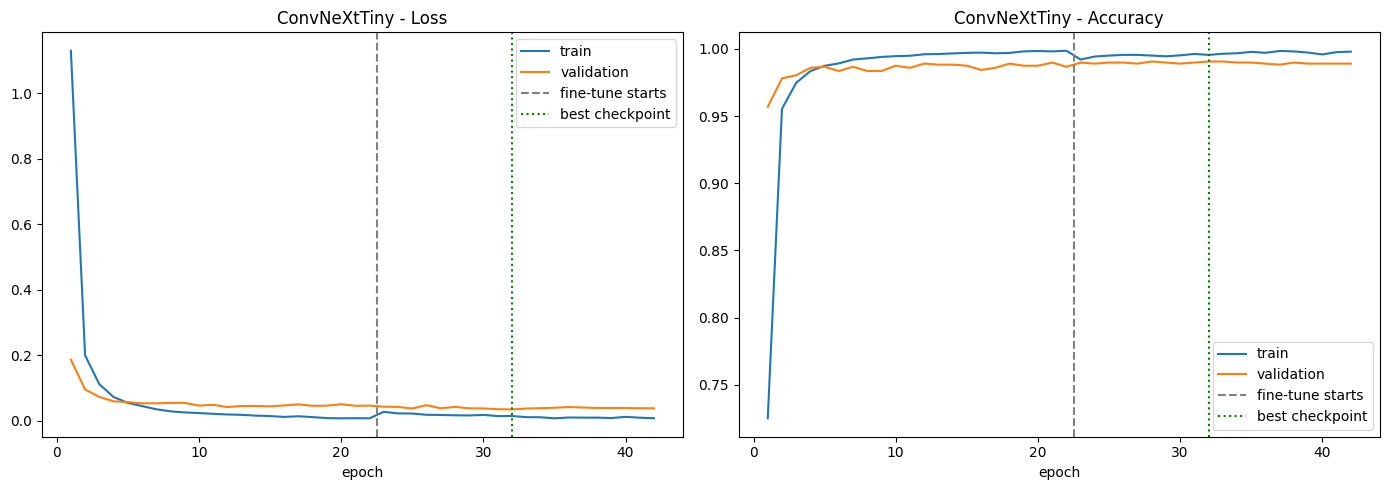

best: epoch 32 (finetune), val_loss 0.0342, val_acc 0.9906


In [10]:
hist = store.read_history()
ep = [r["epoch"] for r in hist]
ft_start = state["stage2_start_epoch"] or 0
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for ax, (k, title) in zip((ax1, ax2), (("loss", "Loss"), ("accuracy", "Accuracy"))):
    ax.plot(ep, [r[k] for r in hist], label="train")
    ax.plot(ep, [r["val_" + k] for r in hist], label="validation")
    ax.axvline(ft_start + 0.5, color="gray", ls="--", label="fine-tune starts")
    b = state["best"]
    if b["epoch"]:
        ax.axvline(b["epoch"], color="green", ls=":", label="best checkpoint")
    ax.set_title(f"{MODEL_ARCH} - {title}"); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "history.png"), dpi=150)
plt.show()
b = state["best"]
if b["epoch"]:
    print(f"best: epoch {b['epoch']} ({b['stage']}), val_loss {b['val_loss']:.4f}, val_acc {b['val_accuracy']:.4f}")

### Cell 8 - Evaluation: validation, test, confusion matrix, misclassified, groups and subgroups

Loss here is plain cross-entropy (no label smoothing), so it can differ slightly from the training log when `LABEL_SMOOTHING` is not 0.

Validation  loss 0.0342 | accuracy 0.9906
Test        loss 0.0607 | accuracy 0.9890 | top-3 0.9969 | macro-F1 0.9836
                         precision    recall  f1-score   support

Andrographis paniculata       1.00      1.00      1.00        16
        Annona muricata       1.00      1.00      1.00        15
       Antidesma bunius       0.88      1.00      0.94        15
       Averrhoa bilimbi       1.00      1.00      1.00        15
           Basella alba       1.00      1.00      1.00        14
     Blumea balsamifera       1.00      1.00      1.00        18
        Boehmeria nivea       1.00      1.00      1.00         8
    Capsicum frutescens       1.00      0.93      0.97        15
         Carmona retusa       0.94      1.00      0.97        15
      Centella asiatica       1.00      1.00      1.00        15
   Citrus aurantiifolia       1.00      1.00      1.00        15
       Citrus aurantium       1.00      0.93      0.96        14
          Citrus maxima       1.00   

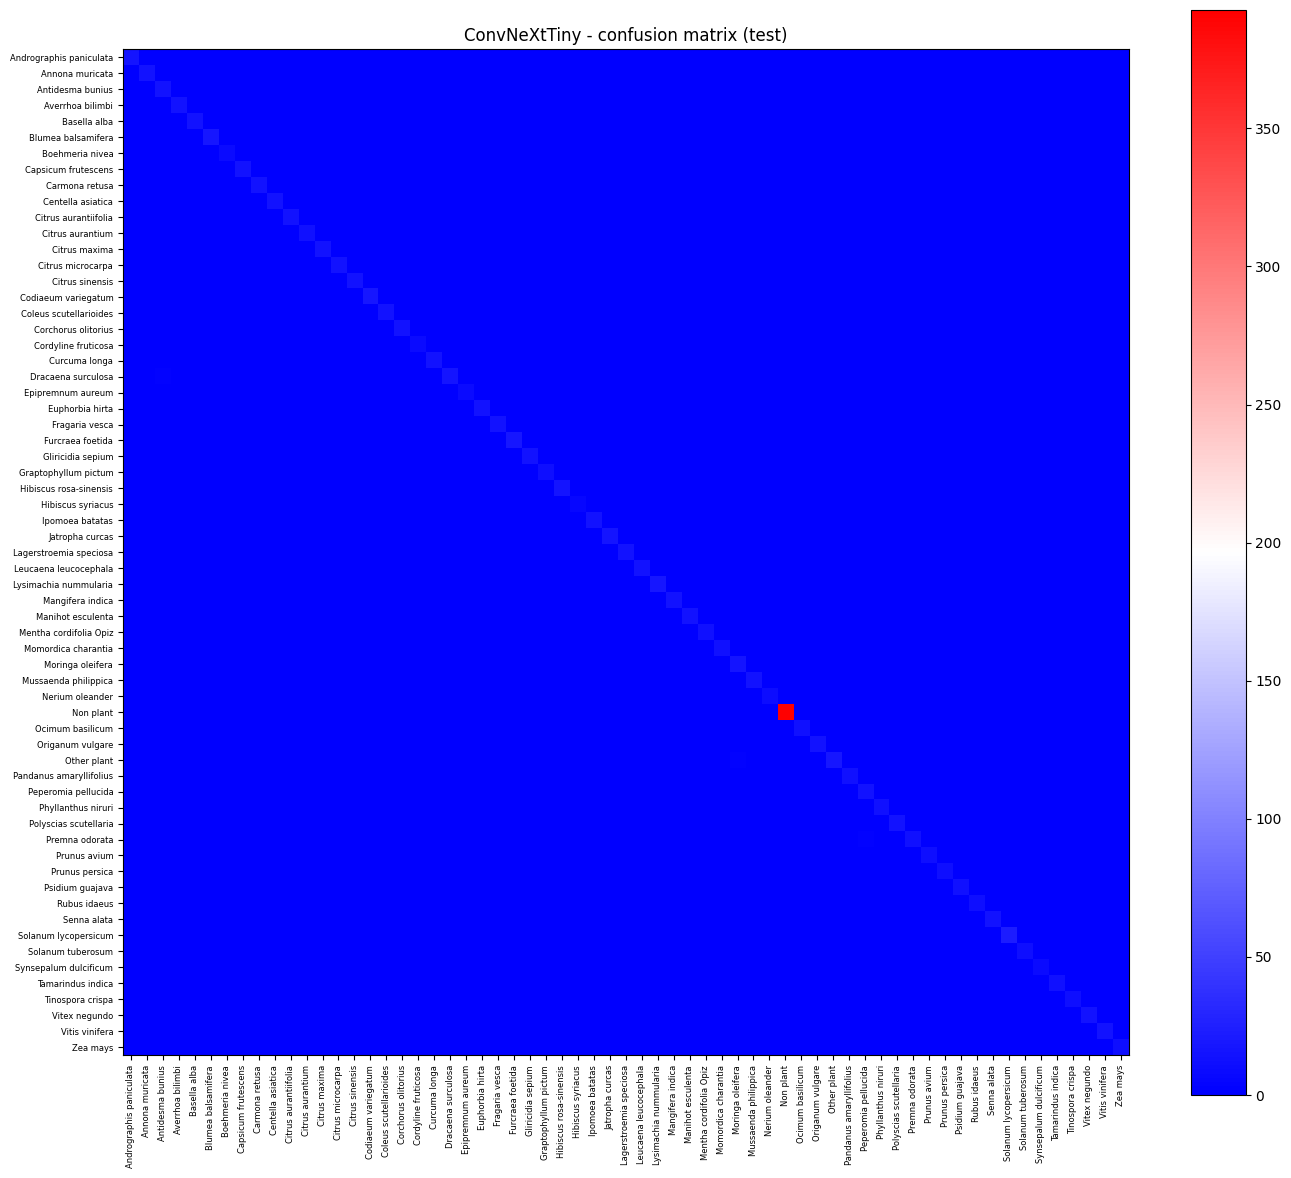

Most confused pairs (true -> predicted):
    3x  Other plant  ->  Moringa oleifera
    2x  Premna odorata  ->  Peperomia pellucida
    2x  Dracaena surculosa  ->  Antidesma bunius
    1x  Peperomia pellucida  ->  Euphorbia hirta
    1x  Other plant  ->  Epipremnum aureum
    1x  Hibiscus syriacus  ->  Jatropha curcas
    1x  Hibiscus syriacus  ->  Epipremnum aureum
    1x  Hibiscus rosa-sinensis  ->  Synsepalum dulcificum
    1x  Citrus aurantium  ->  Prunus persica
    1x  Capsicum frutescens  ->  Carmona retusa

Misclassified: 14 / 1271


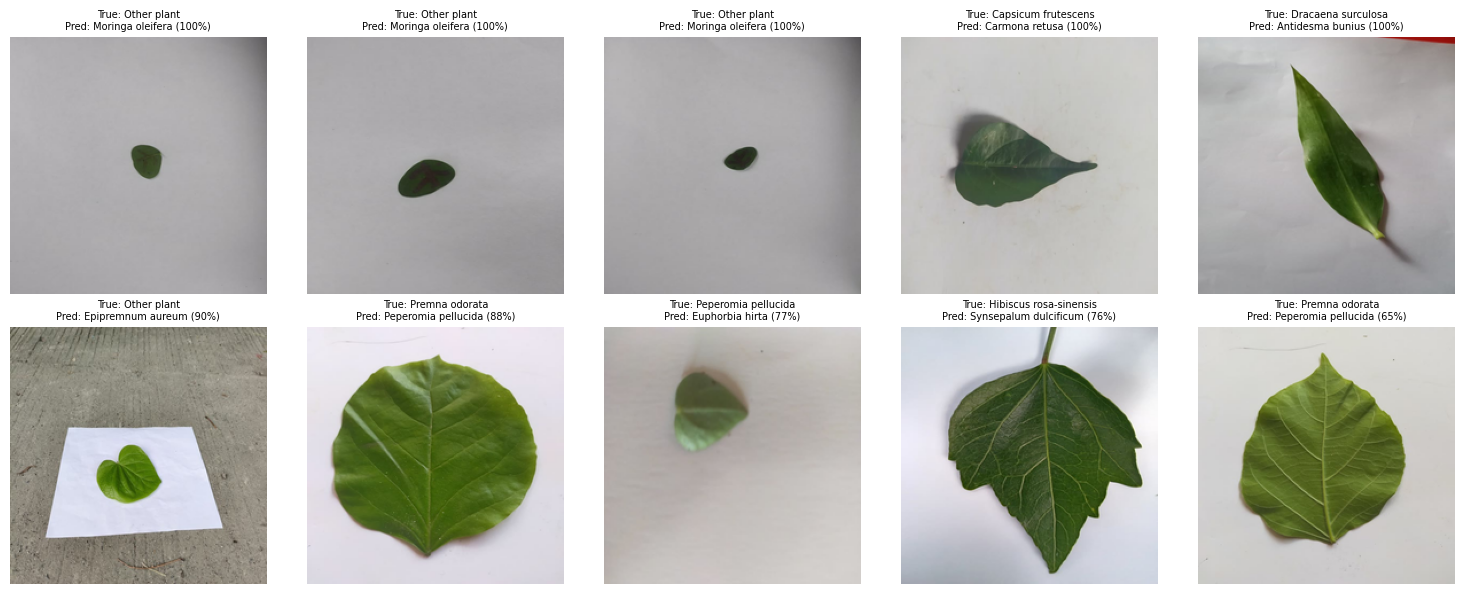


true -> predicted (share of each true group):
                     species     non_plant   other_plant
species               100.0%          0.0%          0.0%   n=857
non_plant               0.0%        100.0%          0.0%   n=393
other_plant            19.0%          0.0%         81.0%   n=21
other_plant  subgroup in train: yes            21 photos | recognised as other_plant: 81.0% | called a species: 19.0%
non_plant    subgroup in train: yes           393 photos | recognised as non_plant: 100.0% | called a species: 0.0%
subgroups most often mistaken for a species:
  other_plant/Christia_obcordata: 38% of 8 photos
  other_plant/Kleinhovia_hospita: 9% of 11 photos


In [11]:
def predict_probs(X):
    return infer.predict(make_dataset(batch_stream(X, None, EVAL_BATCH), False), verbose=0)


def plain_loss(probs, y):
    return float(-np.mean(np.log(np.clip(probs[np.arange(len(y)), y], 1e-9, 1.0))))


val_probs, test_probs = predict_probs(X_val), predict_probs(X_test)
y_pred_val, y_pred = val_probs.argmax(1), test_probs.argmax(1)
val_loss,  val_acc  = plain_loss(val_probs, y_val),   float(np.mean(y_pred_val == y_val))
test_loss, test_acc = plain_loss(test_probs, y_test), float(np.mean(y_pred == y_test))
top3     = float(np.mean([t in np.argsort(p)[-3:] for t, p in zip(y_test, test_probs)]))
macro_f1 = float(f1_score(y_test, y_pred, average="macro", zero_division=0))
print(f"Validation  loss {val_loss:.4f} | accuracy {val_acc:.4f}")
print(f"Test        loss {test_loss:.4f} | accuracy {test_acc:.4f} | top-3 {top3:.4f} | macro-F1 {macro_f1:.4f}")

idx = list(range(NUM_CLASSES))
labels = [class_to_scientific(l) for l in class_labels]
test_report = classification_report(y_test, y_pred, labels=idx, target_names=labels, zero_division=0)
val_report = classification_report(y_val, y_pred_val, labels=idx, target_names=labels, zero_division=0)
print(test_report)
open(os.path.join(OUT_DIR, "test_classification_report.txt"), "w", encoding="utf-8").write(test_report)
open(os.path.join(OUT_DIR, "val_classification_report.txt"), "w", encoding="utf-8").write(val_report)

cm = confusion_matrix(y_test, y_pred, labels=idx)
plt.figure(figsize=(14, 12))
plt.imshow(cm, cmap="bwr"); plt.title(f"{MODEL_ARCH} - confusion matrix (test)"); plt.colorbar()
plt.xticks(idx, labels, rotation=90, fontsize=6); plt.yticks(idx, labels, fontsize=6)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=150); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
print("Most confused pairs (true -> predicted):")
for flat in np.argsort(-off, axis=None)[:10]:
    t, p = np.unravel_index(flat, off.shape)
    if off[t, p] > 0:
        print(f"  {off[t, p]:>3}x  {labels[t]}  ->  {labels[p]}")

# ---- misclassified (what the model saw: the cached, resized photo)
conf = test_probs.max(axis=1)
wrong = np.where(y_pred != y_test)[0]
wrong = wrong[np.argsort(-conf[wrong])]
print(f"\nMisclassified: {len(wrong)} / {len(y_test)}")
with open(os.path.join(OUT_DIR, "misclassified.csv"), "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f); w.writerow(["file", "subgroup", "true", "predicted", "confidence"])
    for i in wrong:
        w.writerow([rel_test[i], sub_test[i], labels[y_test[i]], labels[y_pred[i]], f"{conf[i]:.3f}"])
if len(wrong):
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    for ax, i in zip(axes.flat, wrong[:10]):
        ax.imshow(X_test[i])
        ax.set_title(f"True: {labels[y_test[i]]}\nPred: {labels[y_pred[i]]} ({conf[i]:.0%})", fontsize=7)
        ax.axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "misclassified.png"), dpi=150); plt.show()

# ---- groups: species / non_plant / other_plant
true_k, pred_k = kinds_arr[y_test], kinds_arr[y_pred]
order = ["species", "non_plant", "other_plant"]
print("\ntrue -> predicted (share of each true group):")
print(f"{'':<14}" + "".join(f"{k:>14}" for k in order))
group_rates = {}
for tk in order:
    m = true_k == tk
    if m.any():
        group_rates[tk] = {pk: float(np.mean(pred_k[m] == pk)) for pk in order}
        group_rates[tk]["n"] = int(m.sum())
        print(f"{tk:<14}" + "".join(f"{group_rates[tk][pk]:>14.1%}" for pk in order) + f"   n={m.sum()}")
json.dump(group_rates, open(os.path.join(OUT_DIR, "group_rates.json"), "w"), indent=2)

# ---- subgroups of Non_plant / Other_plant, seen in training or not
train_subs = {k: {s for s, kk in zip(sub_train, kinds_arr[y_train]) if kk == k and s} for k in ("other_plant", "non_plant")}
sub_rows = []
for kind in ("other_plant", "non_plant"):
    sel = np.where(true_k == kind)[0]
    for sub in sorted({sub_test[i] for i in sel}):
        ii = np.array([i for i in sel if sub_test[i] == sub])
        sub_rows.append({"kind": kind, "subgroup": sub or "(none)",
                         "in_train": "yes" if sub in train_subs[kind] else "NO (unseen)", "photos": len(ii),
                         "correct": float(np.mean(y_pred[ii] == y_test[ii])),
                         "called_species": float(np.mean(kinds_arr[y_pred[ii]] == "species"))})
with open(os.path.join(OUT_DIR, "subgroup_report.csv"), "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["kind", "subgroup", "in_train", "photos", "correct", "called_species"])
    w.writeheader(); w.writerows(sub_rows)
for kind in ("other_plant", "non_plant"):
    for flag in ("yes", "NO (unseen)"):
        part = [r for r in sub_rows if r["kind"] == kind and r["in_train"] == flag]
        n = sum(r["photos"] for r in part)
        if n:
            ok = sum(r["correct"] * r["photos"] for r in part) / n
            fa = sum(r["called_species"] * r["photos"] for r in part) / n
            print(f"{kind:<12} subgroup in train: {flag:<12} {n:>4} photos | recognised as {kind}: {ok:.1%} | called a species: {fa:.1%}")
worst = sorted(sub_rows, key=lambda r: -r["called_species"])[:8]
if worst and worst[0]["called_species"] > 0:
    print("subgroups most often mistaken for a species:")
    for r in worst:
        if r["called_species"] > 0:
            print(f"  {r['kind']}/{r['subgroup']}: {r['called_species']:.0%} of {r['photos']} photos")

### Cell 8c - Suggested confidence thresholds

Suggests values for the server's `mlConfidence` setting from the **validation** set (species answers only). Validation also decided early stopping, so treat them as a starting point and confirm with the server in `log` mode.

In [12]:
TARGET   = 0.95     # an "identified" answer should be right at least this often
BAND_MIN = 0.60     # a "Possible X" answer should be right at least this often
MIN_N    = 20       # minimum validation photos behind any suggestion

conf_v   = val_probs.max(axis=1)
pred_v   = val_probs.argmax(axis=1)
margin_v = conf_v - np.sort(val_probs, axis=1)[:, -2]
correct_v = pred_v == y_val
sp = kinds_arr[pred_v] == "species"
grid = np.round(np.arange(0.10, 1.00, 0.01), 2)


def acc(mask):
    return float(correct_v[mask].mean()) if mask.any() else float("nan")


accept = next((float(t) for t in grid if (sp & (conf_v >= t)).sum() >= MIN_N and acc(sp & (conf_v >= t)) >= TARGET), None)
hi = accept if accept is not None else 0.70
uncertain = next((float(t) for t in grid if t < hi and (sp & (conf_v >= t) & (conf_v < hi)).sum() >= MIN_N // 2
                  and acc(sp & (conf_v >= t) & (conf_v < hi)) >= BAND_MIN), None)
print(f"species answers on val: {sp.sum()} of {len(conf_v)} photos")
print("acceptThreshold   :", accept)
print("uncertainThreshold:", uncertain)

lo = uncertain if uncertain is not None else 0.35
band = sp & (conf_v >= lo) & (conf_v < hi)
print(f"\n'Possible X' band [{lo:.2f}, {hi:.2f}): {band.sum()} photos")
for t in (0.0, 0.05, 0.10, 0.15, 0.20, 0.30):
    m = band & (margin_v >= t)
    if m.sum():
        print(f"  margin >= {t:.2f}: {m.sum():3d} photos, {acc(m):5.1%} correct")

suggested_confidence = None
if accept is not None and uncertain is not None and uncertain < accept:
    suggested_confidence = {SERVER_MODEL_ID: {"mode": "log", "acceptThreshold": accept,
                                              "marginThreshold": 0.15, "uncertainThreshold": uncertain}}
    print("\n" + json.dumps(suggested_confidence, indent=2))
    with open(os.path.join(OUT_DIR, "suggested_confidence.json"), "w") as f:
        json.dump(suggested_confidence, f, indent=2)
else:
    print("\nNo reliable suggestion (too few validation photos in the needed ranges, or the target is not reachable). "
          "Keep your current values and rely on log mode.")

species answers on val: 861 of 1275 photos
acceptThreshold   : 0.1
uncertainThreshold: None

'Possible X' band [0.35, 0.10): 0 photos

No reliable suggestion (too few validation photos in the needed ranges, or the target is not reachable). Keep your current values and rely on log mode.


### Cell 9 - Save the deployable model

A clean fp32 copy (no augmentation, no fp16 policy) is written next to the run files. `preprocessing.json` is generated from the same constants the cache was built with.

In [13]:
tf.keras.mixed_precision.set_global_policy("float32")
_, _, _, _, export_model = build_models(pretrained=False)
export_model.set_weights(infer.get_weights())

xb = X_test[:min(32, len(X_test))].astype(np.float32)
diff = float(np.abs(infer.predict(xb, verbose=0) - export_model.predict(xb, verbose=0)).max())
print(f"fp32 export vs trained model, max probability difference: {diff:.5f}")
assert diff < 0.05, "export copy does not match the trained model"

export_model.save(MODEL_PATH)

counts_by_class = np.bincount(y_train, minlength=NUM_CLASSES)
with open(os.path.join(OUT_DIR, "classes.json"), "w", encoding="utf-8") as f:
    json.dump({str(i): {"scientific": class_to_scientific(class_labels[i]), "kind": class_kinds[i],
                        "trainImages": int(counts_by_class[i])} for i in range(NUM_CLASSES)},
              f, indent=2, ensure_ascii=False)

preprocessing = {
    "schema_version": 1, "model": MODEL_ARCH, "model_file": MODEL_FILENAME,
    "height": H, "width": W, "channels": 3, "color_mode": "rgb",
    "exif_transpose": EXIF_TRANSPOSE,            # rotate upright BEFORE resizing (server: preprocess.py)
    "resize": {"method": RESIZE_METHOD, "keep_aspect_ratio": False},
    # pixel = (pixel * rescale - mean) / std on 0-255 values. Identity on purpose: the backbone normalises inside.
    "rescale": 1.0, "mean": [0.0, 0.0, 0.0], "std": [1.0, 1.0, 1.0],
}
with open(os.path.join(OUT_DIR, "preprocessing.json"), "w", encoding="utf-8") as f:
    json.dump(preprocessing, f, indent=2)

hist = store.read_history()
with open(os.path.join(OUT_DIR, "history.json"), "w") as f:
    json.dump({"fine_tune_start_epoch": state["stage2_start_epoch"], "rows": hist}, f, indent=1)

metrics = {
    "arch": MODEL_ARCH, "model_file": MODEL_FILENAME, "input_size": [H, W], "dataset": META["dataset_id"],
    "cache_key": META["key"], "resize": RESIZE_METHOD, "exif_transpose": EXIF_TRANSPOSE,
    "params": int(export_model.count_params()), "classes": NUM_CLASSES,
    "photos": {"train": int(len(y_train)), "val": int(len(y_val)), "test": int(len(y_test))},
    "val_loss": val_loss, "val_accuracy": val_acc, "test_loss": test_loss, "test_accuracy": test_acc,
    "test_top3": top3, "test_macro_f1": macro_f1, "misclassified": int(len(wrong)), "test_images": int(len(y_test)),
    "best_epoch": state["best"]["epoch"], "best_stage": state["best"]["stage"], "epochs_run": state["epochs_done"],
    "group_rates": group_rates,
}
with open(os.path.join(OUT_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)
print("saved:", sorted(p for p in os.listdir(OUT_DIR) if not p.startswith("_old_")))

fp32 export vs trained model, max probability difference: 0.00045
saved: ['best.weights.h5', 'classes.json', 'confusion_matrix.png', 'group_rates.json', 'history.csv', 'history.json', 'history.png', 'last.weights.h5', 'metrics.json', 'misclassified.csv', 'misclassified.png', 'plantellect_model.keras', 'preprocessing.json', 'subgroup_report.csv', 'test_classification_report.txt', 'train_state.json', 'val_classification_report.txt']


### Cell 10 - Verification

In [14]:
with open(os.path.join(OUT_DIR, "classes.json"), encoding="utf-8") as f:
    served = json.load(f)
reloaded = tf.keras.models.load_model(MODEL_PATH)

assert len(served) == reloaded.output_shape[-1], "classes.json and the model come from different runs"
assert all(v["kind"] in ("species", "non_plant", "other_plant") for v in served.values()), "classes.json is missing a valid kind"
assert not any("_" in v["scientific"] for v in served.values()), "underscore translation was skipped"
rdiff = float(np.abs(reloaded.predict(xb, verbose=0) - export_model.predict(xb, verbose=0)).max())
assert rdiff < 1e-5, f"reloaded file differs from the in-memory model ({rdiff})" #1e-4

# --- train/serve parity: the recipe in preprocessing.json must reproduce the cached pixels
with open(os.path.join(OUT_DIR, "preprocessing.json"), encoding="utf-8") as f:
    pre = json.load(f)
assert (pre["height"], pre["width"]) == tuple(reloaded.input_shape[1:3]), "preprocessing.json size does not match the model"


def serve_preprocess(path):
    with Image.open(path) as im:
        if pre.get("exif_transpose"):
            im = ImageOps.exif_transpose(im)
        im = im.convert("RGB").resize((pre["width"], pre["height"]), RESAMPLE[pre["resize"]["method"]])
        arr = np.asarray(im, dtype=np.float32)
    return (arr * pre["rescale"] - np.array(pre["mean"])) / np.array(pre["std"])


parity = META.get("parity", [])
if parity:
    d = [np.abs(serve_preprocess(os.path.join(cache_dir, p["file"])) - X_test[p["test_index"]].astype(np.float32)) for p in parity]
    max_diff, mean_diff = max(float(x.max()) for x in d), float(np.mean([x.mean() for x in d]))
    print(f"serving vs training pixels over {len(parity)} photos: max {max_diff}, mean {mean_diff:.3f}")
    if FAST_DECODE:
        assert mean_diff < 3.0, "serving preprocessing differs from training"
    else:
        assert max_diff <= 1.0, "serving preprocessing differs from training - predictions would be skewed"
else:
    print("no parity photos in this cache; rebuild it to run the parity check")
print("OK - artifacts consistent")

serving vs training pixels over 12 photos: max 0.0, mean 0.000
OK - artifacts consistent


### Cell 11 - Promote to the server (optional)

There is no shared `main` folder any more. With `PROMOTE = True` this copies the three files the server needs into `plantellect/model/_deploy/<server id>/`, ready to place in the server's `ml/model/` folder.

In [16]:
DEPLOY_DIR = DRIVE_ROOT + "/model/_deploy/" + SERVER_MODEL_ID
if PROMOTE:
    for fname in (MODEL_FILENAME, "classes.json", "preprocessing.json"):
        atomic_copy(os.path.join(OUT_DIR, fname), os.path.join(DEPLOY_DIR, fname))
    print("staged for the server:", DEPLOY_DIR)
else:
    print(f"not promoted (PROMOTE = False). When you are happy with this run, set PROMOTE = True; "
          f"the files go to {DEPLOY_DIR}")

staged for the server: /content/drive/MyDrive/plantellect/model/_deploy/convnexttiny
